# 01- Análisis Exploratorio de Datos

Objetivo:
-Comprender la estrucutra del dataset
-Análisis variables numéricas
-Análisis variables categóricas

## 0. Imports

In [2]:
import pandas as pd
import numpy as numpy
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

## 1. Carga del dataset

In [3]:
df = pd.read_csv('../data/rendimiento_estudiantes.csv', sep=';')
print(f'Filas: {df.shape[0]} | Columnas: {df.shape[1]}')

df.head()

Filas: 4424 | Columnas: 37


,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado


In [4]:
#tipos de datos y valores nulos
info = pd.DataFrame({
    'dtype': df.dtypes,
    'nulos': df.isnull().sum(),
    'únicos': df.nunique()
})

print(info.to_string())

                                     dtype  nulos  únicos
estado_civil                        object      0       6
modo_solicitud                      object      0      18
orden_solicitud                      int64      0       8
curso                               object      0      17
asistencia_diurna_vespertina        object      0       2
cualificacion_previa                object      0      17
nota_cualificacion_previa          float64      0     101
nacionalidad                        object      0      21
cualificacion_madre                 object      0      29
cualificacion_padre                 object      0      34
ocupacion_madre                     object      0      32
ocupacion_padre                     object      0      46
nota_admision                      float64      0     620
desplazado                          object      0       2
necesidades_educativas_especiales   object      0       2
deudor                              object      0       2
matricula_al_d

In [5]:
#separamos variables por tipo

vars_numericas = df.select_dtypes(include='number').columns.tolist()
vars_categoricas = df.select_dtypes(include='object').columns.tolist()
#excluimos el target
vars_categoricas = [i for i in vars_categoricas if i!= 'objetivo']

print(f"Variables numéricas ({len(vars_numericas)}): {vars_numericas}")
print(f"\nVariables categóricas ({len(vars_categoricas)}): {vars_categoricas}")


Variables numéricas (19): ['orden_solicitud', 'nota_cualificacion_previa', 'nota_admision', 'edad_al_matricularse', 'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas', 'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion', 'asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas', 'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion', 'pib']

Variables categóricas (17): ['estado_civil', 'modo_solicitud', 'curso', 'asistencia_diurna_vespertina', 'cualificacion_previa', 'nacionalidad', 'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre', 'desplazado', 'necesidades_educativas_especiales', 'deudor', 'matricula_al_dia', 'genero', 'becado', 'internacional']


## 2. Variable objetivo

             total  porcentaje %
objetivo                        
graduado      2209          49.9
abandono      1421          32.1
matriculado    794          17.9


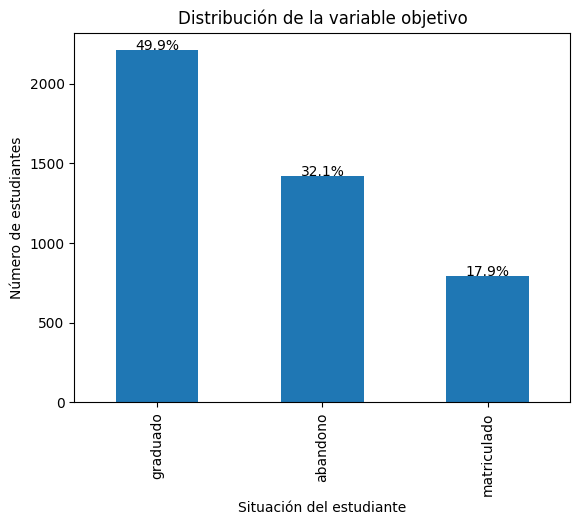

In [9]:
conteo = df['objetivo'].value_counts()
porcentaje = df['objetivo'].value_counts(normalize=True) * 100

vista_obj = pd.DataFrame({'total': conteo, 'porcentaje %': porcentaje.round(1)})
print(vista_obj)

#creamos gráfico para visualizarlo
plt.figure()

conteo.plot(kind='bar')

#añadimos porcentajes encima
for i,v in enumerate(conteo.values):
    plt.text(i, v, f"{porcentaje.values[i]:.1f}%", ha='center')

plt.title('Distribución de la variable objetivo')
plt.xlabel('Situación del estudiante')
plt.ylabel('Número de estudiantes')

#la guardamos en figuras
plt.savefig('../figuras/distribucion_objetivo.png')
plt.show()

En la distribución de la variable objetivo vemos un ligero desbalanceo entre clases. La categoría mayoritaría (graduado) vemos casi el 50% de las observaciones, mientras que las otras dos clases presentantan proporciones del 32% y 18%, respectivamente.

Este desbalanceo, aunque no extremo, puede influir en el comportamiento de los modelos de clasificaicón que veremos más adelante, por lo que será importante tenerlo en cuenta al evaluar los resultados.

## 3. Variables numéricas

In [10]:
#estadísitcas descriptivas
df[vars_numericas].describe().round(2)

,orden_solicitud,nota_cualificacion_previa,nota_admision,edad_al_matricularse,asignaturas_1sem_convalidadas,asignaturas_1sem_matriculadas,asignaturas_1sem_evaluadas,asignaturas_1sem_aprobadas,nota_media_1sem,asignaturas_1sem_sin_evaluacion,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib
count,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00
mean,1.73,132.61,126.98,23.27,0.71,6.27,8.30,4.71,10.64,0.14,0.54,6.23,8.06,4.44,10.23,0.15,11.57,1.23,0.00
std,1.31,13.19,14.48,7.59,2.36,2.48,4.18,3.09,4.84,0.69,1.92,2.20,3.95,3.01,5.21,0.75,2.66,1.38,2.27
min,0.00,95.00,95.00,17.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,7.60,-0.80,-4.06
25%,1.00,125.00,117.90,19.00,0.00,5.00,6.00,3.00,11.00,0.00,0.00,5.00,6.00,2.00,10.75,0.00,9.40,0.30,-1.70
50%,1.00,133.10,126.10,20.00,0.00,6.00,8.00,5.00,12.29,0.00,0.00,6.00,8.00,5.00,12.20,0.00,11.10,1.40,0.32
75%,2.00,140.00,134.80,25.00,0.00,7.00,10.00,6.00,13.40,0.00,0.00,7.00,10.00,6.00,13.33,0.00,13.90,2.60,1.79
max,9.00,190.00,190.00,70.00,20.00,26.00,45.00,26.00,18.88,12.00,19.00,23.00,33.00,20.00,18.57,12.00,16.20,3.70,3.51


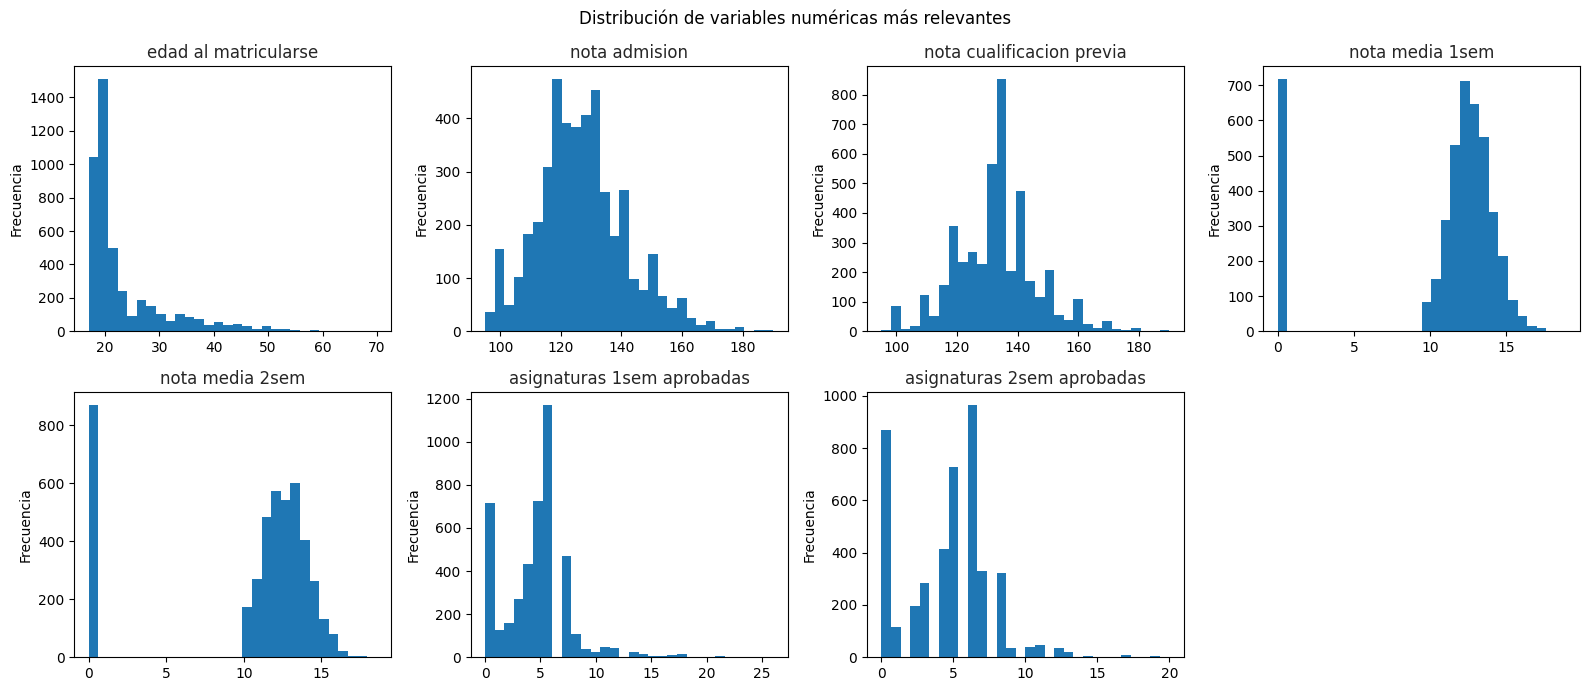

In [17]:
#vemos distribución de las variables numéricas más relevantes
vars_plot = [
    'edad_al_matricularse', 'nota_admision', 'nota_cualificacion_previa',
    'nota_media_1sem', 'nota_media_2sem',
    'asignaturas_1sem_aprobadas', 'asignaturas_2sem_aprobadas'
]


fig, axes = plt.subplots(2,4, figsize=(16,7))
axes = axes.flatten()

for i,var in enumerate(vars_plot):
    axes[i].hist(df[var].dropna(), bins=30)
    axes[i].set_title(var.replace('_', ' '), alpha=0.85) #mantenemos los titulos sin el _
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frecuencia')



#ocultar si sale algún subplot vacío
for j in range(len(vars_plot), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Distribución de variables numéricas más relevantes')
plt.tight_layout()
plt.savefig('../figuras/histogramas_numericas.png')
plt.show()


Vemos que las variables numéricas presentan distribuciones heterogéneas. Algunas, como la nota d eadmision o la edad, muestran una dispersión moderada; mientras que lasrelacionadas con los distintos semestres muestran mayor variabiliad entre estudiantes.

## 4. Relación variables numéricas y objetivo

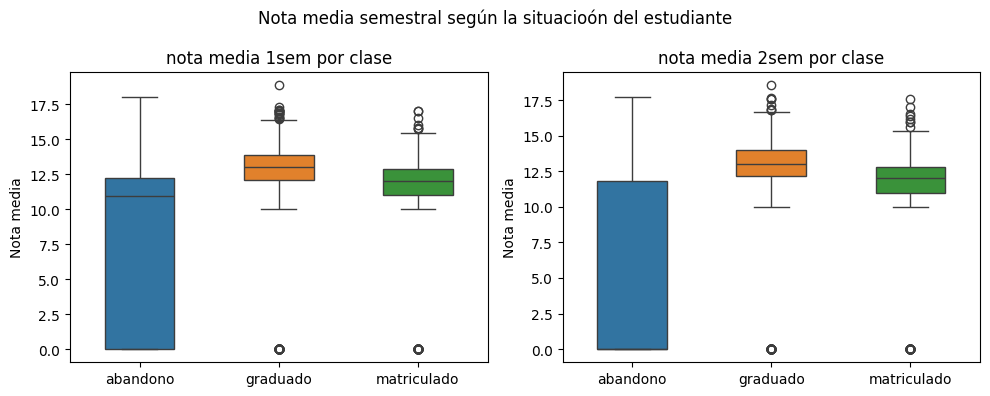

In [30]:
#boxplots de las notas medias
fig, axes = plt.subplots(1,2, figsize=(10,4))

for ax, var in zip(axes, ['nota_media_1sem', 'nota_media_2sem']):
    sns.boxplot(data=df, x='objetivo', y=var, hue='objetivo', legend=False, ax= ax, width=0.5)
    ax.set_title(f'{var.replace("_", " ")} por clase')
    ax.set_xlabel('')
    ax.set_ylabel('Nota media')

fig.suptitle('Nota media semestral según la situacioón del estudiante')
plt.tight_layout()
plt.savefig('../figuras/boxplot_notas_por_clase.png')
plt.show()

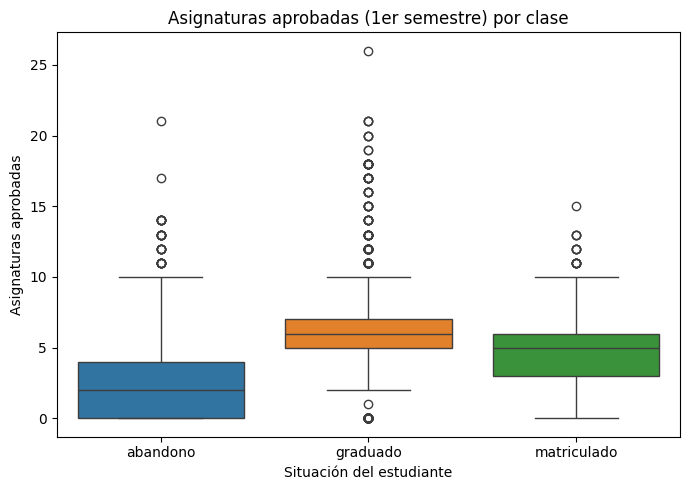

In [31]:
#boxplot: asignaturas aprobadas 1er semestre por clse

plt.figure(figsize=(7,5))

sns.boxplot(data=df, x='objetivo', y='asignaturas_1sem_aprobadas', hue='objetivo', legend=False)
plt.title('Asignaturas aprobadas (1er semestre) por clase')
plt.xlabel('Situación del estudiante')
plt.ylabel('Asignaturas aprobadas')


plt.tight_layout()
plt.savefig('../figuras/boxplot_aprobadas_1sem.png')
plt.show()

Observamos diferencias claras entre las clases en las variables de rendimiento académico. Los estudiantes que abandonan tienen en general, como es de esperar, menores notas medias y menos asignaturas aprobadas (aunque con varios outliers), mientras que los grduados muestran los valores más altos. Los matriculados se sitúan en posición intermedia.